# Experiment 9: Object Detection and Recognition Using Deep Learning Models

**Name:** Harshit Dubey  
**Section:** C  
**University Roll No.:** CU24250109

## Aim

To implement a deep learning-based object detection and recognition system using a pre-trained YOLOv8 model on standard COCO images, and evaluate its detections using bounding boxes, class labels, confidence scores, and inference time.

## Purpose

Object detection combines object localization and classification. A detector identifies one or more objects in an image, draws a bounding box around each object, assigns a class label, and reports a confidence score. This experiment uses YOLOv8 because it provides a practical balance between speed and accuracy for real-time computer-vision applications.

## Dataset and Model

- **Dataset:** Microsoft COCO sample images, downloaded from public Ultralytics assets.
- **Model:** Pre-trained YOLOv8n, trained on the 80-class COCO dataset.
- **Framework:** Ultralytics YOLO with OpenCV, NumPy, Pandas, and Matplotlib.

## Prerequisites

Python, Jupyter Notebook, OpenCV, NumPy, Matplotlib, basic CNN knowledge, and an internet connection for the first model download.


In [7]:
# Install the detector and table dependency once if they are not already available.
%pip install -q ultralytics pandas


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
from pathlib import Path
from time import perf_counter

import cv2
import matplotlib.pyplot as plt
import pandas as pd
import requests
from IPython.display import display
from ultralytics import YOLO

IMAGE_DIR = Path("experiment_9_images")
IMAGE_DIR.mkdir(exist_ok=True)
print("OpenCV:", cv2.__version__)
print("Images will be stored in:", IMAGE_DIR.resolve())

OpenCV: 5.0.0
Images will be stored in: /home/harshit/College_WORK/Computer-Vision-Lab-2026-27-ODD-Sem-3rd-Year-Section-C/Experiment 9 - Solutions by students/labsheet-9-Harshit-Dubey-section-c-cu24250109/experiment_9_images


In [9]:
# Download two public COCO-style sample images for reproducible inference.
image_urls = {
    "bus.jpg": "https://ultralytics.com/images/bus.jpg",
    "zidane.jpg": "https://ultralytics.com/images/zidane.jpg",
}

for filename, url in image_urls.items():
    destination = IMAGE_DIR / filename
    if not destination.exists():
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        destination.write_bytes(response.content)
    print(f"{filename}: {destination.stat().st_size / 1024:.1f} KB")

bus.jpg: 134.2 KB
zidane.jpg: 49.2 KB


## Load the Pre-trained YOLOv8 Model

YOLO predicts bounding-box coordinates, objectness, and class probabilities in one forward pass. Non-maximum suppression removes highly overlapping duplicate boxes. The small `yolov8n.pt` model is selected for fast CPU inference; larger variants generally improve accuracy at the cost of speed and memory.


In [10]:
model = YOLO("yolov8n.pt")
print("Model loaded:", model.model_name if hasattr(model, "model_name") else "YOLOv8n")
print("Number of COCO classes:", len(model.names))

Model loaded: yolov8n.pt
Number of COCO classes: 80


## Run Inference and Build a Detection Table

A detection is retained when its confidence is at least 0.25. The table records the image, class, confidence, box coordinates, and inference time. In a labelled benchmark, precision, recall, mAP, and IoU against ground-truth boxes would be used for formal evaluation; these sample images demonstrate qualitative detection and speed.


In [11]:
confidence_threshold = 0.25
results = {}
detection_rows = []

for image_path in sorted(IMAGE_DIR.glob("*.jpg")):
    start = perf_counter()
    prediction = model.predict(source=str(image_path), conf=confidence_threshold, verbose=False)[0]
    elapsed_ms = (perf_counter() - start) * 1000
    results[image_path.name] = prediction

    boxes = prediction.boxes
    for box in boxes:
        class_id = int(box.cls.item())
        x1, y1, x2, y2 = [round(value, 1) for value in box.xyxy[0].tolist()]
        detection_rows.append({
            "image": image_path.name,
            "class": model.names[class_id],
            "confidence": round(float(box.conf.item()), 3),
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2,
            "inference_ms": round(elapsed_ms, 1),
        })

print(f"Processed {len(results)} images")
detection_table = pd.DataFrame(detection_rows)
display(detection_table)

Processed 2 images


/home/harshit/College_WORK/Computer-Vision-Lab-2026-27-ODD-Sem-3rd-Year-Section-C/.venv/lib64/python3.14/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


,image,class,confidence,x1,y1,x2,y2,inference_ms
0,bus.jpg,bus,0.873,22.9,231.3,805.0,756.8,171.6
1,bus.jpg,person,0.866,48.6,398.6,245.3,902.7,171.6
2,bus.jpg,person,0.853,669.5,392.2,809.7,877.0,171.6
3,bus.jpg,person,0.825,221.5,405.8,345.0,857.5,171.6
4,bus.jpg,person,0.261,0.0,550.5,63.0,873.4,171.6
5,bus.jpg,stop sign,0.255,0.1,254.5,32.6,324.9,171.6
6,zidane.jpg,person,0.836,114.9,197.4,1114.5,711.9,39.9
7,zidane.jpg,person,0.819,748.5,41.9,1143.1,713.0,39.9
8,zidane.jpg,tie,0.291,439.5,437.1,524.3,709.2,39.9


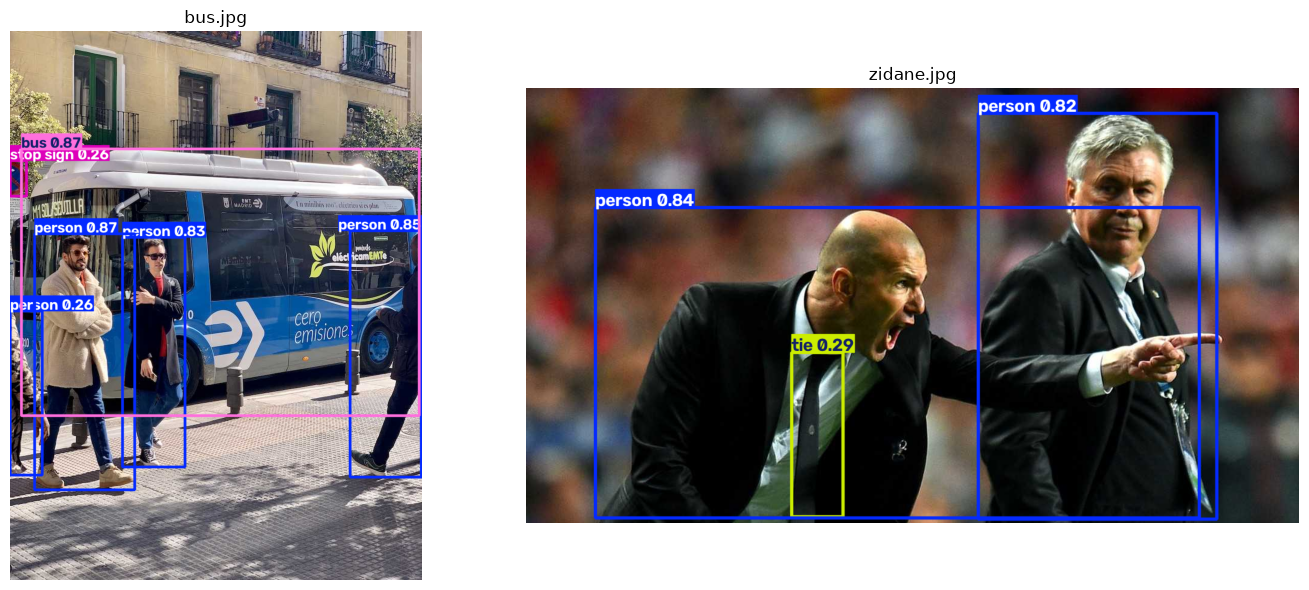

In [12]:
# Plot the model's annotated predictions.
fig, axes = plt.subplots(1, len(results), figsize=(15, 6), squeeze=False)
for axis, (filename, prediction) in zip(axes[0], results.items()):
    annotated = cv2.cvtColor(prediction.plot(), cv2.COLOR_BGR2RGB)
    axis.imshow(annotated)
    axis.set_title(filename)
    axis.axis("off")
plt.tight_layout()
plt.show()

In [13]:
# Summarize detections and inference speed.
if not detection_table.empty:
    summary = (detection_table.groupby("class")
               .agg(detections=("class", "size"), mean_confidence=("confidence", "mean"))
               .sort_values("detections", ascending=False))
    display(summary.round(3))

    speed_summary = detection_table.groupby("image")["inference_ms"].first()
    print("Mean inference time: %.1f ms/image" % speed_summary.mean())
    print("Approximate throughput: %.2f images/second" % (1000 / speed_summary.mean()))
else:
    print("No detections passed the confidence threshold.")

,detections,mean_confidence
class,,
person,6,0.743
bus,1,0.873
stop sign,1,0.255
tie,1,0.291


Mean inference time: 105.8 ms/image
Approximate throughput: 9.46 images/second


## Observations and Analysis

1. YOLOv8n detects several COCO object categories and reports their locations in a single inference pass.
2. Higher confidence scores indicate that the model is more certain about a prediction, but they do not guarantee correctness.
3. Inference time depends on image size, hardware, model variant, and whether the first run includes model warm-up.
4. The lightweight YOLOv8n model is suitable for real-time prototypes and edge devices. Larger YOLO models or Faster R-CNN may be preferred when accuracy is more important than latency.
5. A formal benchmark requires ground-truth annotations and metrics such as precision, recall, mAP@0.5, mAP@0.5:0.95, and IoU. The downloaded images are used here for a reproducible demonstration, not for claiming benchmark accuracy.

## Advantages and Limitations

**Advantages:** end-to-end learning, good real-time speed, support for many classes, direct localization, and easy transfer learning using pre-trained weights.  
**Limitations:** performance can fall for small, occluded, blurred, or unusual objects; confidence thresholds affect false positives and missed detections; and pre-trained models may inherit dataset bias. Model weights and inference also require substantial compute compared with traditional handcrafted methods.

## Conclusion

A pre-trained YOLOv8 detector successfully recognized and localized objects in standard COCO sample images. The experiment demonstrates the complete object-detection workflow: preparing input images, loading a pre-trained CNN detector, running inference, filtering predictions, visualizing bounding boxes, recording confidence scores, and measuring speed. For production use, the model should be evaluated on a representative labelled dataset and optimized for the target hardware and safety requirements.


## Viva Questions and Answers

### 1. Differentiate image classification, object detection, and image segmentation.

**Image classification** assigns one or more labels to a complete image. **Object detection** assigns labels and rectangular bounding boxes to individual objects. **Image segmentation** assigns a class to every relevant pixel; instance segmentation additionally separates different objects of the same class.

### 2. Explain the working principle of YOLO.

YOLO divides the task into one neural-network prediction. The network extracts image features and directly predicts candidate box coordinates, objectness scores, and class probabilities. Non-maximum suppression keeps the best-scoring boxes while removing duplicate overlapping predictions.

### 3. Compare YOLO, SSD, and Faster R-CNN.

YOLO is generally the fastest and is suitable for real-time video. SSD is also a one-stage detector with good speed and a simple deployment path. Faster R-CNN is a two-stage detector that proposes regions and then classifies/refines them; it often provides strong accuracy but has higher latency and compute cost. The best choice depends on accuracy, speed, hardware, and application constraints.

### 4. What is a bounding box and why is it important?

A bounding box is a rectangle represented by coordinates such as `(x1, y1, x2, y2)` around an object. It localizes the object, enables measurement and tracking, and provides the spatial output needed for downstream actions.

### 5. Explain confidence score and IoU.

A confidence score estimates how likely a predicted box contains a particular class. IoU, or Intersection over Union, is the ratio of the intersection area to the union area of two boxes: $IoU = \frac{Area(A \cap B)}{Area(A \cup B)}$. IoU measures localization overlap and is used in non-maximum suppression and evaluation against ground truth.

### 6. Advantages of pre-trained models over traditional image processing.

Pre-trained models learn robust visual features from large datasets, handle changes in appearance better than handcrafted rules, support transfer learning, and provide strong results with less labelled data and development time. Traditional methods can be faster for very constrained tasks but are usually less general.

### 7. Why are MS COCO and Pascal VOC widely used?

They provide standardized images, class definitions, bounding-box annotations, and established evaluation protocols. Their public benchmarks make it possible to compare models fairly and reproduce research results.

### 8. Five real-world applications.

1. Autonomous vehicle perception
2. CCTV and intrusion monitoring
3. Retail inventory and checkout analytics
4. Medical image localization
5. Industrial defect and safety inspection

### 9. Common challenges in complex environments.

Occlusion, small objects, cluttered backgrounds, poor lighting, motion blur, viewpoint changes, similar-looking classes, crowded scenes, domain shift, and limited or biased training data can all reduce detection accuracy.

### 10. How can object detection be improved?

Performance can be improved using larger and better-labelled datasets, data augmentation, transfer learning, hyperparameter tuning, larger or newer detector architectures, multi-scale feature fusion, improved loss functions, knowledge distillation, model ensembling, and hardware-aware quantization or pruning.
